In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Dataset Head:
   class                                              tweet
0      2  !!! RT @mayasolovely: As a woman you shouldn't...
1      1  !!!!! RT @mleew17: boy dats cold...tyga dwn ba...
2      1  !!!!!!! RT @UrKindOfBrand Dawg!!!! RT @80sbaby...
3      1  !!!!!!!!! RT @C_G_Anderson: @viva_based she lo...
4      1  !!!!!!!!!!!!! RT @ShenikaRoberts: The shit you...

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24783 entries, 0 to 24782
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   class   24783 non-null  int64 
 1   tweet   24783 non-null  object
dtypes: int64(1), object(1)
memory usage: 387.4+ KB
None


/tmp/ipython-input-3644557926.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='class', data=df, palette='viridis')


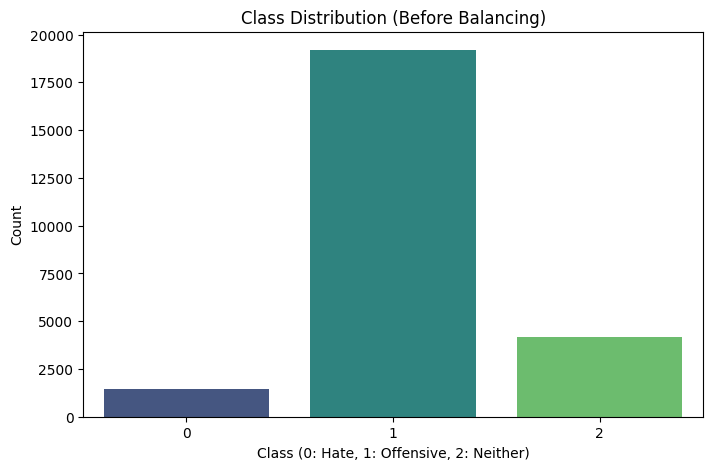


Class Counts:
 class
1    19190
2     4163
0     1430
Name: count, dtype: int64


In [2]:
# Load the Dataset
dataset_url = "https://media.geeksforgeeks.org/wp-content/uploads/20250321123144355200/Dataset---Hate-Speech-Detection-using-Deep-Learning.csv"
df = pd.read_csv(dataset_url)

# Inspect the Data
print("Dataset Head:")
print(df.head())
print("\nDataset Info:")
print(df.info())

# Visualize Class Distribution
plt.figure(figsize=(8, 5))
sns.countplot(x='class', data=df, palette='viridis')
plt.title('Class Distribution (Before Balancing)')
plt.xlabel('Class (0: Hate, 1: Offensive, 2: Neither)')
plt.ylabel('Count')
plt.show()

# Check actual counts
print("\nClass Counts:\n", df['class'].value_counts())

In [7]:
import numpy as np
import pandas as pd
import re
import nltk
import pickle
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.utils import class_weight
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from tensorflow.keras.backend import clear_session
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout, SpatialDropout1D, Bidirectional
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

# Setup Resources
twitter_stopwords = {'rt', 'amp'}
nltk.download('stopwords')
nltk.download('wordnet')
stop_words = set(stopwords.words('english'))
stop_words.update(twitter_stopwords)
stemmer = PorterStemmer()

# 1. Cleaning the Text
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'[^\w\s]', '', text)
    words = text.split()
    words = [stemmer.stem(w) for w in words if w not in stop_words]
    return " ".join(words)

df['clean_tweet'] = df['tweet'].apply(clean_text)

# 2. Data Splitting
X_all = df['clean_tweet'].values
y_all = df['class'].values

# Split 80% for Dev (CV & Training), 20% for Final Testing
X_dev, X_test_final, y_dev, y_test_final = train_test_split(
    X_all, y_all, test_size=0.2, stratify=y_all, random_state=42
)

print(f"Total Data: {len(X_all)}")
print(f"Development Set (for CV): {len(X_dev)}")
print(f"Held-out Test Set: {len(X_test_final)}")

# Parameters
FOLDS = 5
MAX_WORDS = 5000
MAX_LEN = 100
BATCH_SIZE = 32
EPOCHS = 15

# 3. Cross-Validation on Development Set
# We only use X_dev and y_dev here
kfold = StratifiedKFold(n_splits=FOLDS, shuffle=True, random_state=42)
cv_accuracies = []
fold_no = 1

print(f"\nStarting {FOLDS}-Fold Stratified Cross-Validation on DEVELOPMENT SET...\n")

for train_index, val_index in kfold.split(X_dev, y_dev):
    print(f"--- FOLD {fold_no} / {FOLDS} ---")

    # Split Dev data into Train/Val for this fold
    X_fold_train, X_fold_val = X_dev[train_index], X_dev[val_index]
    y_fold_train, y_fold_val = y_dev[train_index], y_dev[val_index]

    # Compute Class Weights
    fold_weights = class_weight.compute_class_weight(
        class_weight='balanced',
        classes=np.unique(y_fold_train),
        y=y_fold_train
    )
    class_weight_dict = dict(enumerate(fold_weights))

    # Tokenize (Fit only on fold training data)
    tokenizer = Tokenizer(num_words=MAX_WORDS, oov_token='<OOV>')
    tokenizer.fit_on_texts(X_fold_train)

    X_train_seq = tokenizer.texts_to_sequences(X_fold_train)
    X_val_seq = tokenizer.texts_to_sequences(X_fold_val)
    X_train_pad = pad_sequences(X_train_seq, maxlen=MAX_LEN, padding='pre', truncating='post')
    X_val_pad = pad_sequences(X_val_seq, maxlen=MAX_LEN, padding='pre', truncating='post')

    y_train_enc = to_categorical(y_fold_train, num_classes=3)
    y_val_enc = to_categorical(y_fold_val, num_classes=3)

    # Build Model
    clear_session()
    model = Sequential()
    model.add(Embedding(input_dim=MAX_WORDS, output_dim=128))
    model.add(SpatialDropout1D(0.3))
    model.add(Bidirectional(LSTM(64, dropout=0.3, recurrent_dropout=0.3)))
    model.add(Dense(32, activation='relu'))
    model.add(Dropout(0.3))
    model.add(Dense(3, activation='softmax'))

    optimizer = Adam(learning_rate=0.0001)
    model.compile(loss='categorical_crossentropy', optimizer=optimizer, metrics=['accuracy'])

    # Train
    es = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True, verbose=0)
    model.fit(
        X_train_pad, y_train_enc,
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        validation_data=(X_val_pad, y_val_enc),
        class_weight=class_weight_dict,
        callbacks=[es],
        verbose=0
    )

    # Evaluate
    scores = model.evaluate(X_val_pad, y_val_enc, verbose=0)
    print(f"Fold {fold_no} Accuracy: {scores[1]*100:.2f}%")
    cv_accuracies.append(scores[1])
    fold_no += 1

# Summary of CV Results
print("\n" + "="*30)
print("CROSS VALIDATION RESULTS")
print("="*30)
print(f"Individual Scores: {[f'{acc*100:.2f}%' for acc in cv_accuracies]}")
print(f"Mean Accuracy:     {np.mean(cv_accuracies)*100:.2f}%")
print(f"Standard Dev:      {np.std(cv_accuracies)*100:.2f}%")
print("="*30)

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


Total Data: 24783
Development Set (for CV): 19826
Held-out Test Set: 4957

Starting 5-Fold Stratified Cross-Validation on DEVELOPMENT SET...

--- FOLD 1 / 5 ---
Fold 1 Accuracy: 82.63%
--- FOLD 2 / 5 ---
Fold 2 Accuracy: 82.65%
--- FOLD 3 / 5 ---
Fold 3 Accuracy: 83.88%
--- FOLD 4 / 5 ---
Fold 4 Accuracy: 84.56%
--- FOLD 5 / 5 ---
Fold 5 Accuracy: 84.69%

CROSS VALIDATION RESULTS
Individual Scores: ['82.63%', '82.65%', '83.88%', '84.56%', '84.69%']
Mean Accuracy:     83.68%
Standard Dev:      0.90%


Epoch 1/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 163s 276ms/step - accuracy: 0.5556 - loss: 1.1053 - val_accuracy: 0.7463 - val_loss: 0.9326
Epoch 2/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 151s 271ms/step - accuracy: 0.7207 - loss: 0.9310 - val_accuracy: 0.7912 - val_loss: 0.6316
Epoch 3/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 206s 278ms/step - accuracy: 0.7510 - loss: 0.6739 - val_accuracy: 0.7827 - val_loss: 0.5955
Epoch 4/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 165s 295ms/step - accuracy: 0.7624 - loss: 0.5887 - val_accuracy: 0.7948 - val_loss: 0.5740
Epoch 5/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 155s 279ms/step - accuracy: 0.7678 - loss: 0.5724 - val_accuracy: 0.8114 - val_loss: 0.5283
Epoch 6/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 204s 282ms/step - accuracy: 0.7926 - loss: 0.5008 - val_accuracy: 0.8245 - val_loss: 0.4760
Epoch 7/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 153s 274ms/step - accuracy: 0.8174 - loss: 0.4546 - val_accuracy: 0.8225 - val_loss: 0.4713
Epoch 8/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 157s 282ms/step - accuracy: 0.8317 -

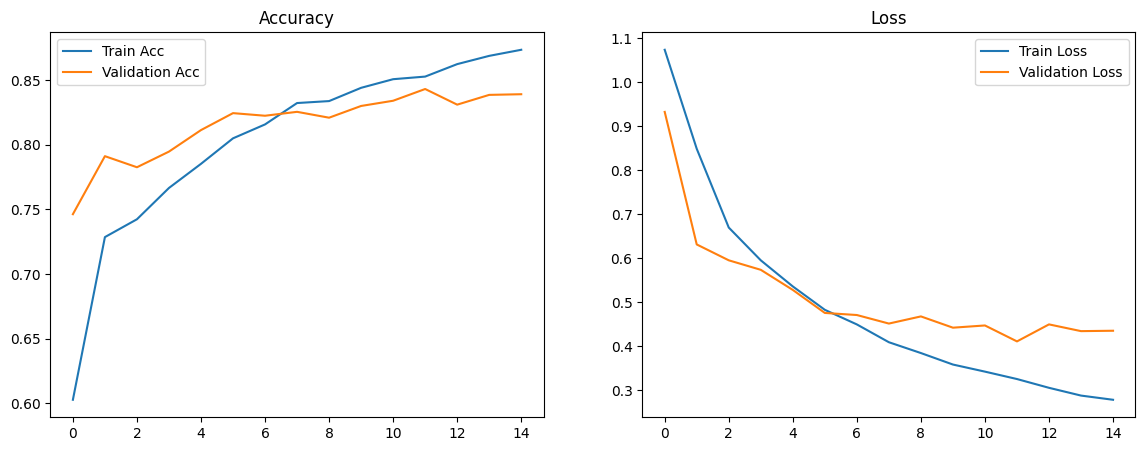


FINAL TEST SET EVALUATION
155/155 ━━━━━━━━━━━━━━━━━━━━ 10s 57ms/step


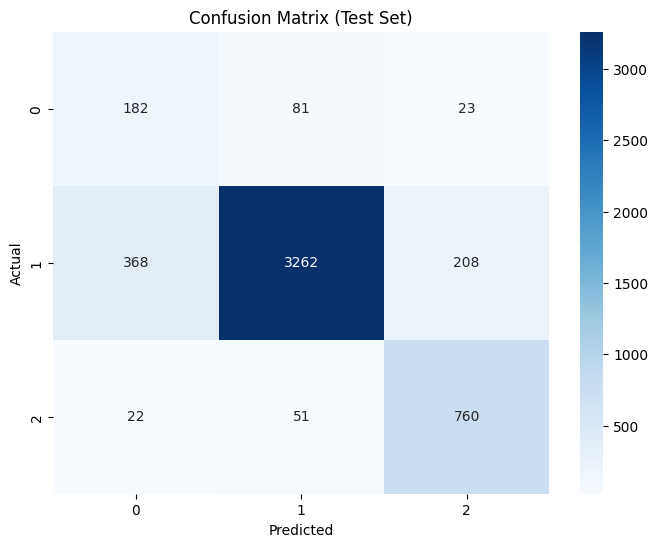

              precision    recall  f1-score   support

           0       0.32      0.64      0.42       286
           1       0.96      0.85      0.90      3838
           2       0.77      0.91      0.83       833

    accuracy                           0.85      4957
   macro avg       0.68      0.80      0.72      4957
weighted avg       0.89      0.85      0.86      4957



In [8]:
# 4. Final Model Training on Full Dev Set
final_tokenizer = Tokenizer(num_words=MAX_WORDS, oov_token='<OOV>')
final_tokenizer.fit_on_texts(X_dev)

X_dev_seq = final_tokenizer.texts_to_sequences(X_dev)
X_test_final_seq = final_tokenizer.texts_to_sequences(X_test_final)

X_dev_pad = pad_sequences(X_dev_seq, maxlen=MAX_LEN, padding='pre', truncating='post')
X_test_final_pad = pad_sequences(X_test_final_seq, maxlen=MAX_LEN, padding='pre', truncating='post')

y_dev_enc = to_categorical(y_dev, num_classes=3)
y_test_final_enc = to_categorical(y_test_final, num_classes=3)

# Fixing imbalance using class weights
final_weights = class_weight.compute_class_weight(
    class_weight='balanced', classes=np.unique(y_dev), y=y_dev
)
final_weights_dict = dict(enumerate(final_weights))

# Build Model
clear_session()
model = Sequential()
model.add(Embedding(input_dim=MAX_WORDS, output_dim=128))
model.add(SpatialDropout1D(0.3))
model.add(Bidirectional(LSTM(64, dropout=0.3, recurrent_dropout=0.3)))
model.add(Dense(32, activation='relu'))
model.add(Dropout(0.3))
model.add(Dense(3, activation='softmax'))

optimizer = Adam(learning_rate=0.0001)
model.compile(loss='categorical_crossentropy', optimizer=optimizer, metrics=['accuracy'])

# Train Model
history = model.fit(
    X_dev_pad, y_dev_enc,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_split=0.1, # Use 10% of Dev set for Early Stopping checks
    class_weight=final_weights_dict,
    callbacks=[EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)],
    verbose=1
)


print("\nSaving artifacts...")
model.save('sentiment_model.keras')
with open('tokenizer.pickle', 'wb') as handle:
    pickle.dump(final_tokenizer, handle, protocol=pickle.HIGHEST_PROTOCOL)

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Validation Acc')
plt.title('Accuracy')
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss')
plt.legend()
plt.show()

# 5. Evaluation
print("\n" + "="*30)
print("FINAL TEST SET EVALUATION")
print("="*30)

y_pred_probs = model.predict(X_test_final_pad)
y_pred_classes = np.argmax(y_pred_probs, axis=1)
y_true_classes = np.argmax(y_test_final_enc, axis=1)

cm = confusion_matrix(y_true_classes, y_pred_classes)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix (Test Set)')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

print(classification_report(y_true_classes, y_pred_classes))